# Level 2 — Task 3: Clustering Analysis (K-Means)

**Assignment objectives:** standardize the dataset; apply K-Means; use the elbow method to select the number of clusters; visualize clusters with a 2D scatter plot.

**Dataset:** the supplied Iris dataset. The model uses the four numeric measurement columns. The `species` label is not used to train K-Means.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## 1. Load the data and select numerical features

In [2]:
iris = pd.read_csv("data/iris.csv")
feature_columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = iris[feature_columns]

print("Dataset shape:", iris.shape)
X.head()

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 2. Standardize the numerical features

Standardization puts measurements on comparable scales before calculating distances for K-Means.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. Use the elbow method

Fit K-Means for several cluster counts and record the within-cluster sum of squares (inertia). The elbow is the point where adding more clusters starts reducing inertia less sharply.

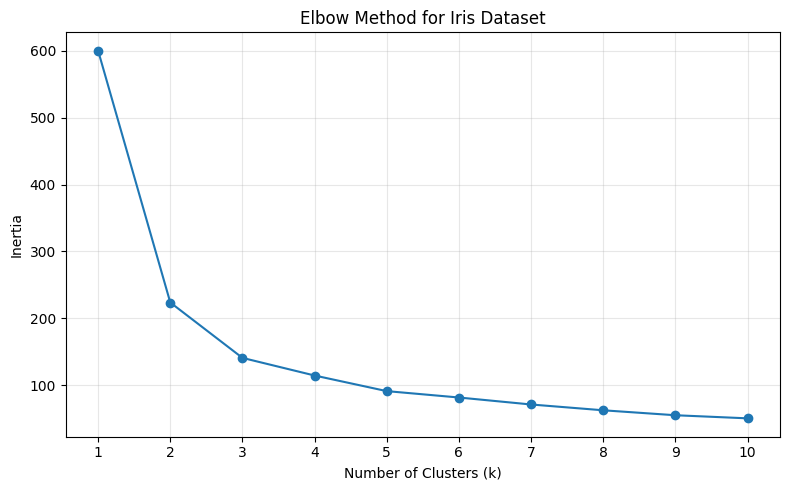

In [4]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Iris Dataset")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The elbow curve shows a strong reduction up to around **3 clusters**, followed by smaller gains. Use `k=3` for the final K-Means model.

## 4. Fit K-Means with 3 clusters and visualize in 2D

The model is fitted using all four standardized features. The visualization displays the resulting clusters against petal length and petal width.

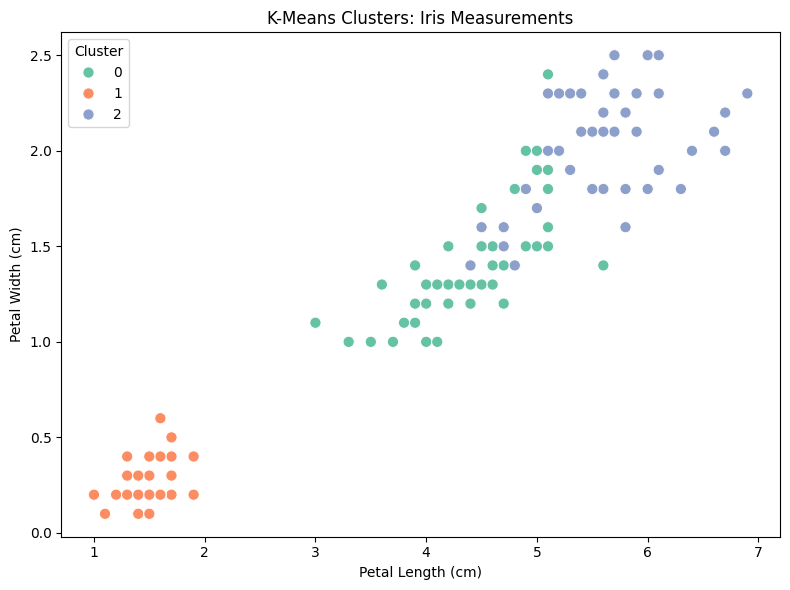

cluster
0    53
1    50
2    47
Name: count, dtype: int64

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
iris["cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=iris,
    x="petal_length",
    y="petal_width",
    hue="cluster",
    palette="Set2",
    s=65
)
plt.title("K-Means Clusters: Iris Measurements")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

iris["cluster"].value_counts().sort_index()

## Task 3 checklist

- [x] Standardize the numerical features.
- [x] Apply K-Means and use the elbow method to select a cluster count.
- [x] Visualize the clusters using a 2D scatter plot.